# Section 5 — Strategic Options: ควรทำอะไรก่อน
**Business Question:** ในบรรดาทางเลือกเชิงกลยุทธ์ มีทางไหนคุ้มค่าที่สุดเมื่อเทียบกับขีดความสามารถจริงของ Shopee?

### ทางเลือกเชิงกลยุทธ์ 4 ทาง (4 Strategic Options)
1. **(1) Protect Intent-based Base:** ป้องกันฐานผู้ซื้อที่ตั้งใจค้นหาสินค้า (Search / Shopee Mall / การจัดส่งไวผ่าน SPX Express)
2. **(2) Selective Shoppertainment / Affiliate:** ลงทุน Live & Affiliate เฉพาะหมวดสินค้าที่ Margin สูง (ไม่เผาเงินหว่านทุกหมวดแข่งกับ TikTok)
3. **(3) Regulatory Tailwind / OTOP Moat:** ใช้ลมหนุนกฎหมายใหม่ ดึงผู้ขายไทยและ OTOP (เรต 4%) เข้าแพลตฟอร์มเพื่อสร้างสินค้า Exclusive ท้องถิ่น
4. **(4) Full-scale Quick Commerce:** ทุ่มงบเปิดศึกส่งด่วนระดับชั่วโมงเต็มรูปแบบแข่งกับแพลตฟอร์มเดลิเวอรีและร้านสะดวกซื้อ

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

opt_df = pd.read_csv("../data/processed/sec05_strategic_options.csv")
scen_df = pd.read_csv("../data/processed/sec05_scenarios.csv")
display(opt_df)
display(scen_df)

,option_id,option_name,short_label,feasibility_score,impact_score,investment_mb,risk_score,risk_label
0,1,(1) ป้องกันฐาน Intent-based (Search + Mall + SPX),(1) Protect Intent Base,8.5,8.8,1200,2.5,ความเสี่ยงต่ำ (Low)
1,2,(2) Selective Shoppertainment & Affiliate,(2) Selective Affiliate/Live,7.0,7.6,1800,5.2,ความเสี่ยงปานกลาง (Medium)
2,3,(3) Regulatory Tailwind (Local SME + OTOP 4%),(3) Regulatory & OTOP Moat,8.8,7.9,850,2.0,ความเสี่ยงต่ำ (Low)
3,4,(4) รุก Quick Commerce เต็มรูปแบบ,(4) Full Quick Commerce,3.4,6.4,3500,8.5,ความเสี่ยงสูง (High)


,option_label,worst_case_pct,base_case_pct,best_case_pct
0,(1) Protect Intent Base,12.0,24.5,32.0
1,(3) Regulatory & OTOP Moat,10.5,21.0,28.5
2,(2) Selective Affiliate/Live,3.5,16.0,26.0
3,(4) Full Quick Commerce,-18.0,4.5,18.0


### กราฟ 5.1 — Impact vs Feasibility Matrix (Bubble 2x2)
- **สื่ออะไร:** ทางเลือก **(1) ป้องกันฐาน Intent-based** และ **(3) ขยายฐาน Local/OTOP รับลมหนุนรัฐ** อยู่ใน Quadrant *"โอกาสสูง + ทำได้จริง"* โดยใช้งบลงทุนต่ำกว่าและมีความเสี่ยงต่ำกว่า ขณะที่ **(4) Quick Commerce** ใช้เงินทุนมหาศาลแต่มีความเป็นไปได้ต่ำและเสี่ยงสูง

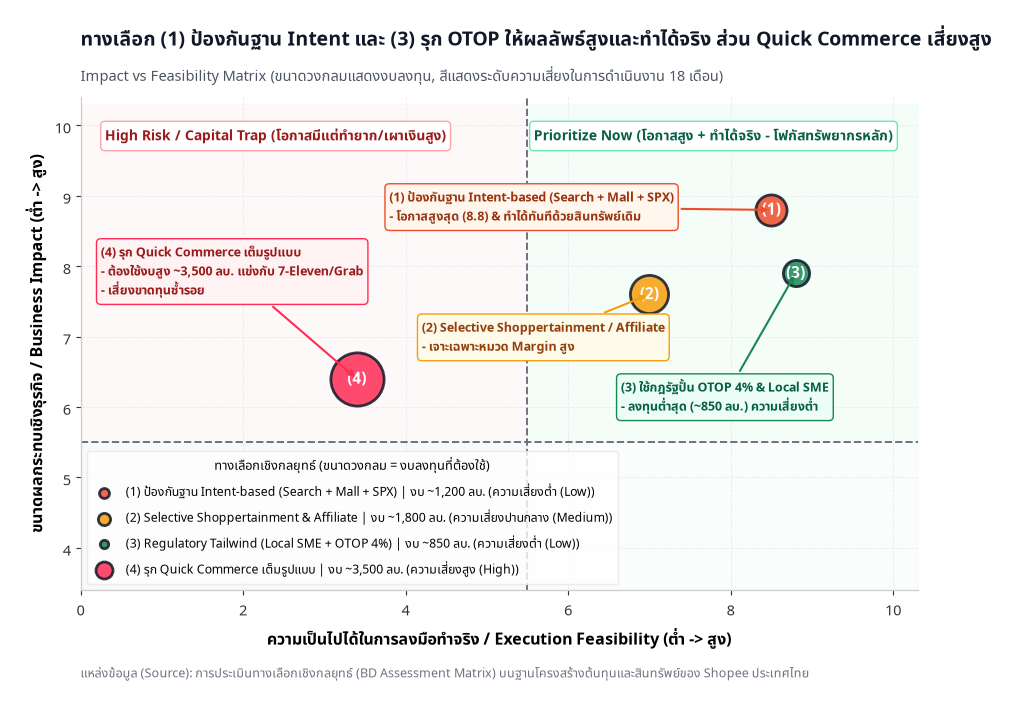

In [2]:
fig, ax = plt.subplots(figsize=(10.8, 6.4))

ax.axvline(5.5, color="#6B7280", linestyle="--", linewidth=1.4, zorder=2)
ax.axhline(5.5, color="#6B7280", linestyle="--", linewidth=1.4, zorder=2)

ax.fill_between([5.5, 10.3], 5.5, 10.3, color="#ECFDF5", alpha=0.5, zorder=1)
ax.fill_between([0.0, 5.5], 5.5, 10.3, color="#FEF2F2", alpha=0.45, zorder=1)
ax.fill_between([5.5, 10.3], 0.0, 5.5, color="#F9FAFB", alpha=0.5, zorder=1)
ax.fill_between([0.0, 5.5], 0.0, 5.5, color="#F3F4F6", alpha=0.5, zorder=1)

ax.text(10.0, 10.0, "Prioritize Now (โอกาสสูง + ทำได้จริง - โฟกัสทรัพยากรหลัก)",
        ha="right", va="top", fontsize=10, fontweight="bold", color="#065F46",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#6EE7B7"))
ax.text(0.3, 10.0, "High Risk / Capital Trap (โอกาสมีแต่ทำยาก/เผาเงินสูง)",
        ha="left", va="top", fontsize=10, fontweight="bold", color="#991B1B",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFFFFF", edgecolor="#FCA5A5"))

risk_colors = {
    1: COLORS["Shopee"],
    2: "#F59E0B",
    3: COLORS["OTOP"],
    4: COLORS["TikTok Red"]
}

for _, row in opt_df.iterrows():
    oid = int(row["option_id"])
    fx = row["feasibility_score"]
    iy = row["impact_score"]
    inv = row["investment_mb"]
    c = risk_colors[oid]

    ax.scatter(fx, iy, s=inv * 0.42, color=c, alpha=0.85, edgecolors="#111827", linewidths=2.0,
               label=f'{row["option_name"]} | งบ ~{inv:,} ลบ. ({row["risk_label"]})', zorder=4)
    ax.text(fx, iy, f"({oid})", ha="center", va="center", fontsize=11, fontweight="bold", color="#FFFFFF", zorder=5)

ax.annotate(
    "(1) ป้องกันฐาน Intent-based (Search + Mall + SPX)\n- โอกาสสูงสุด (8.8) & ทำได้ทันทีด้วยสินทรัพย์เดิม",
    xy=(8.5, 8.8), xytext=(3.8, 8.65),
    fontsize=9.0, fontweight="bold", color="#9A3412",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFF7ED", edgecolor=COLORS["Shopee"]),
    arrowprops=dict(arrowstyle="->", color=COLORS["Shopee"], lw=1.5),
    zorder=6
)

ax.annotate(
    "(3) ใช้กฎรัฐปั้น OTOP 4% & Local SME\n- ลงทุนต่ำสุด (~850 ลบ.) ความเสี่ยงต่ำ",
    xy=(8.8, 7.9), xytext=(6.65, 5.95),
    fontsize=9.0, fontweight="bold", color="#065F46",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#ECFDF5", edgecolor=COLORS["OTOP"]),
    arrowprops=dict(arrowstyle="->", color=COLORS["OTOP"], lw=1.5),
    zorder=6
)

ax.annotate(
    "(2) Selective Shoppertainment / Affiliate\n- เจาะเฉพาะหมวด Margin สูง",
    xy=(7.0, 7.6), xytext=(4.2, 6.8),
    fontsize=9.0, fontweight="bold", color="#92400E",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FFFBEB", edgecolor="#F59E0B"),
    arrowprops=dict(arrowstyle="->", color="#F59E0B", lw=1.5),
    zorder=6
)

ax.annotate(
    "(4) รุก Quick Commerce เต็มรูปแบบ\n- ต้องใช้งบสูง ~3,500 ลบ. แข่งกับ 7-Eleven/Grab\n- เสี่ยงขาดทุนซ้ำรอย",
    xy=(3.4, 6.4), xytext=(0.25, 7.6),
    fontsize=9.0, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FEF2F2", edgecolor=COLORS["TikTok Red"]),
    arrowprops=dict(arrowstyle="->", color=COLORS["TikTok Red"], lw=1.5),
    zorder=6
)

ax.set_xlabel("ความเป็นไปได้ในการลงมือทำจริง / Execution Feasibility (ต่ำ -> สูง)", fontweight="bold")
ax.set_ylabel("ขนาดผลกระทบเชิงธุรกิจ / Business Impact (ต่ำ -> สูง)", fontweight="bold")
ax.set_xlim(0, 10.3)
ax.set_ylim(3.4, 10.4)
ax.legend(loc="lower left", fontsize=8.8, markerscale=0.32, labelspacing=0.6,
          title="ทางเลือกเชิงกลยุทธ์ (ขนาดวงกลม = งบลงทุนที่ต้องใช้)", title_fontsize=9.2)

chart_style.add_title_and_source(
    ax,
    title="ทางเลือก (1) ป้องกันฐาน Intent และ (3) รุก OTOP ให้ผลลัพธ์สูงและทำได้จริง ส่วน Quick Commerce เสี่ยงสูง",
    subtitle="Impact vs Feasibility Matrix (ขนาดวงกลมแสดงงบลงทุน, สีแสดงระดับความเสี่ยงในการดำเนินงาน 18 เดือน)",
    source_text="การประเมินทางเลือกเชิงกลยุทธ์ (BD Assessment Matrix) บนฐานโครงสร้างต้นทุนและสินทรัพย์ของ Shopee ประเทศไทย"
)

plt.savefig("../charts/05_1_impact_vs_feasibility_matrix.png")
plt.show()

### กราฟ 5.2 — Scenario Comparison (Best / Base / Worst Case)
- **สื่ออะไร:** เปรียบเทียบความไม่แน่นอนของผลตอบแทนใน 18 เดือน — ทางเลือก (1) และ (3) ให้ผลตอบแทนเป็นบวกแม้ในกรณีเลวร้ายที่สุด (Worst Case +12.0% และ +10.5%) ในขณะที่ Quick Commerce มีโอกาสติดลบหนักถึง **-18.0%**

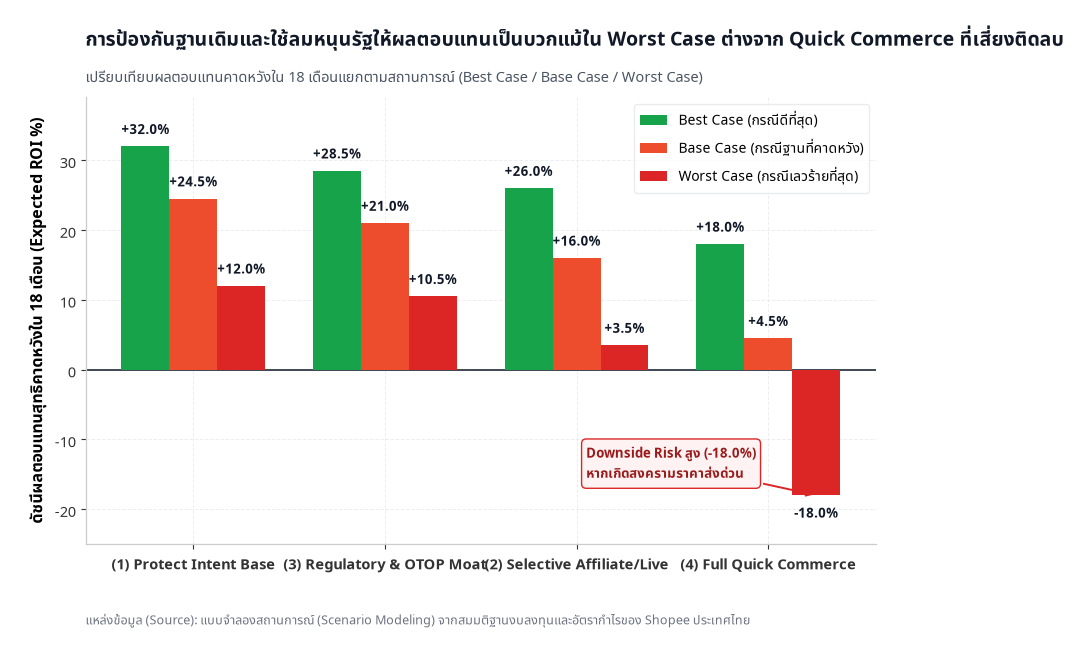

In [3]:
fig, ax = plt.subplots(figsize=(10.2, 5.8))

options = scen_df["option_label"].tolist()
x = np.arange(len(options))
width = 0.25

r_best = ax.bar(x - width, scen_df["best_case_pct"], width, label="Best Case (กรณีดีที่สุด)", color="#16A34A", zorder=3)
r_base = ax.bar(x, scen_df["base_case_pct"], width, label="Base Case (กรณีฐานที่คาดหวัง)", color=COLORS["Shopee"], zorder=3)
r_worst = ax.bar(x + width, scen_df["worst_case_pct"], width, label="Worst Case (กรณีเลวร้ายที่สุด)", color="#DC2626", zorder=3)

ax.axhline(0, color="#1F2937", linewidth=1.2, zorder=2)

for bars in [r_best, r_base, r_worst]:
    for b in bars:
        h = b.get_height()
        va = "bottom" if h >= 0 else "top"
        offset = 0.9 if h >= 0 else -1.2
        ax.text(b.get_x() + b.get_width()/2, h + offset, f"{h:+.1f}%",
                ha="center", va=va, fontsize=9.5, fontweight="bold", color="#111827")

ax.annotate(
    "Downside Risk สูง (-18.0%)\nหากเกิดสงครามราคาส่งด่วน",
    xy=(3 + width, -18.0), xytext=(2.05, -15.5),
    fontsize=9.5, fontweight="bold", color="#991B1B",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#FEF2F2", edgecolor="#DC2626"),
    arrowprops=dict(arrowstyle="->", color="#DC2626", lw=1.4)
)

ax.set_xticks(x)
ax.set_xticklabels(options, fontsize=10.5, fontweight="bold")
ax.set_ylabel("ดัชนีผลตอบแทนสุทธิคาดหวังใน 18 เดือน (Expected ROI %)", fontweight="bold")
ax.set_ylim(-25, 39)
ax.legend(loc="upper right")

chart_style.add_title_and_source(
    ax,
    title="การป้องกันฐานเดิมและใช้ลมหนุนรัฐให้ผลตอบแทนเป็นบวกแม้ใน Worst Case ต่างจาก Quick Commerce ที่เสี่ยงติดลบ",
    subtitle="เปรียบเทียบผลตอบแทนคาดหวังใน 18 เดือนแยกตามสถานการณ์ (Best Case / Base Case / Worst Case)",
    source_text="แบบจำลองสถานการณ์ (Scenario Modeling) จากสมมติฐานงบลงทุนและอัตรากำไรของ Shopee ประเทศไทย"
)

plt.savefig("../charts/05_2_scenario_comparison.png")
plt.show()

> **Insight ของ Section 5:** *"การเผาเงินแข่ง Shoppertainment แบบปูพรมหรือเปิดศึก Quick Commerce ให้ ROI ต่ำกว่าและเสี่ยงกว่าการป้องกันฐาน Intent-based เดิมควบคู่กับการใช้ลมหนุนภาครัฐ (OTOP 4%)"*